# Tugas Praktikum: Multiple Linear Regression

Dataset insurance.csv berisi data biaya medis personal. Variabel adalah : 
1. age (usia) 
2. sex (jenis kelamin)
3. bmi (indeks massa tubuh)
4. children (jumlah anak/tanggungan)
5. smoker (status merokok) 
6. region (wilayah) 

Targetnya adalah charges (biaya medis)

In [1]:
# Langkah 1: Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Langkah 2: Baca dan Pahami Data
data = pd.read_csv('data/insurance.csv')
display(data.head())
print('Ukuran data:', data.shape)
data.info()
display(data.describe())
print('Jumlah nilai kosong:')
print(data.isna().sum())
print('Jumlah baris duplikat:', data.duplicated().sum())

# Menghapus baris yang sama agar tidak muncul di data latih dan uji.
data = data.drop_duplicates().reset_index(drop=True)
print('Ukuran data setelah dibersihkan:', data.shape)

Ukuran data: (1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
Jumlah nilai kosong:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Jumlah baris duplikat: 1
Ukuran data setelah dibersihkan: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


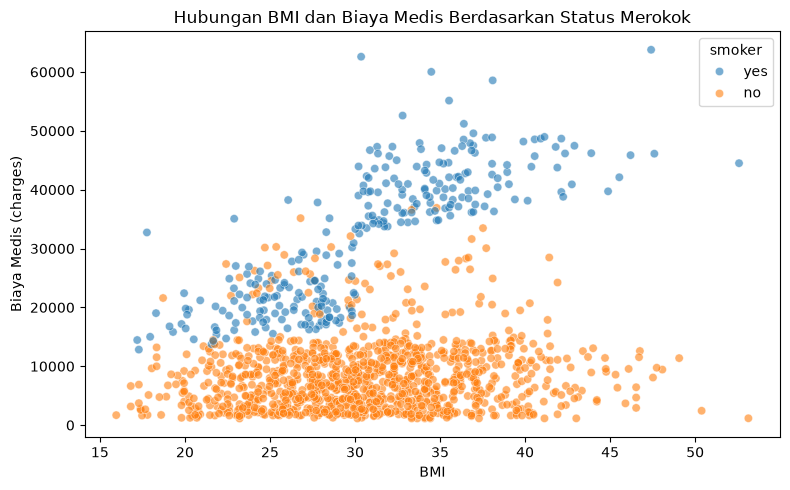

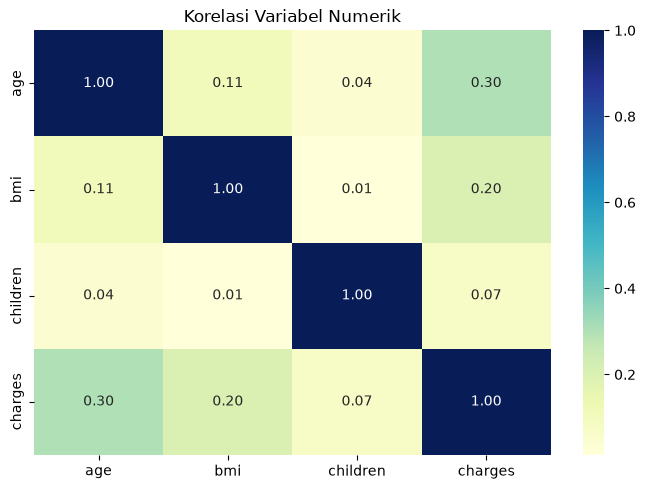

In [3]:
# Langkah 3: Visualisasi Data
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x='bmi', y='charges', hue='smoker', alpha=0.6)
plt.title('Hubungan BMI dan Biaya Medis Berdasarkan Status Merokok')
plt.xlabel('BMI')
plt.ylabel('Biaya Medis (charges)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(data.corr(numeric_only=True), cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Korelasi Variabel Numerik')
plt.tight_layout()
plt.show()

In [4]:
# Langkah 4: Tentukan Fitur dan Target, Lalu Bagi Data
X = data[['age', 'sex', 'bmi', 'children', 'smoker', 'region']]
y = data['charges']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data latih: 935
Jumlah data uji: 402


In [5]:
# Langkah 5: Encoding Kategori dan Feature Scaling
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

fitur_numerik = ['age', 'bmi', 'children']
fitur_kategori = ['sex', 'smoker', 'region']

preprocessor = ColumnTransformer([
    ('numerik', StandardScaler(), fitur_numerik),
    ('kategori', OneHotEncoder(drop='first', handle_unknown='ignore',
                               sparse_output=False), fitur_kategori)
])

# Fit hanya pada data latih agar informasi data uji tidak ikut dipelajari.
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)
print('Ukuran fitur data latih:', X_train_scaled.shape)
print('Ukuran fitur data uji:', X_test_scaled.shape)

Ukuran fitur data latih: (935, 8)
Ukuran fitur data uji: (402, 8)


In [6]:
# Langkah 6: Latih Model Multiple Linear Regression
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train_scaled, y_train)

print('Intercept:', regressor.intercept_)
koefisien = pd.DataFrame({
    'Fitur': preprocessor.get_feature_names_out(),
    'Koefisien': regressor.coef_
})
display(koefisien)

Intercept: 9142.58119200699


,Fitur,Koefisien
0,numerik__age,3735.582882
1,numerik__bmi,1881.418482
2,numerik__children,670.293556
3,kategori__sex_male,-193.762821
4,kategori__smoker_yes,23999.487160
5,kategori__region_northwest,-368.212875
6,kategori__region_southeast,-576.346248
7,kategori__region_southwest,-1184.388910


In [7]:
# Langkah 7: Prediksi pada Data Uji
y_pred = regressor.predict(X_test_scaled)

hasil_prediksi = pd.DataFrame({
    'Biaya Aktual': y_test,
    'Biaya Prediksi': y_pred,
    'Residual': y_test - y_pred
})
display(hasil_prediksi.head(10))

,Biaya Aktual,Biaya Prediksi,Residual
12,1826.84300,4081.403131,-2254.560131
306,20177.67113,4609.892514,15567.778616
318,7421.19455,8576.347139,-1155.152589
815,2842.76075,2240.882052,601.878698
157,15518.18025,25119.094952,-9600.914702
244,29523.16560,37997.201264,-8474.035664
642,4466.62140,6950.136837,-2483.515437
968,8596.82780,11901.784262,-3304.956462
142,18972.49500,29936.719854,-10964.224854
1033,12950.07120,16164.124519,-3214.053319


In [8]:
# Langkah 8: Evaluasi Model
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r_squared = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print('R-squared:', r_squared)
print('MSE:', mse)
print('MAE:', mae)
print('RMSE:', rmse)

R-squared: 0.7573516713161301
MSE: 31814749.200477127
MAE: 3974.5930455277385
RMSE: 5640.456470931863


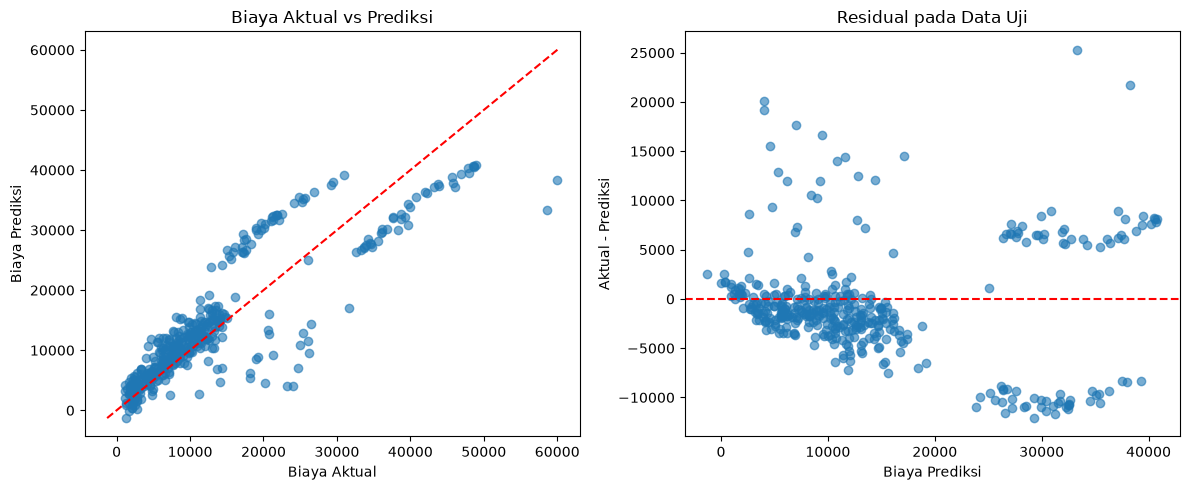

In [9]:
# Langkah 9: Visualisasi Hasil Prediksi dan Residual
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred, alpha=0.6)
batas_min = min(y_test.min(), y_pred.min())
batas_max = max(y_test.max(), y_pred.max())
axes[0].plot([batas_min, batas_max], [batas_min, batas_max], 'r--')
axes[0].set_title('Biaya Aktual vs Prediksi')
axes[0].set_xlabel('Biaya Aktual')
axes[0].set_ylabel('Biaya Prediksi')

res = y_test - y_pred
axes[1].scatter(y_pred, res, alpha=0.6)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residual pada Data Uji')
axes[1].set_xlabel('Biaya Prediksi')
axes[1].set_ylabel('Aktual - Prediksi')

plt.tight_layout()
plt.show()

R-squared data uji adalah 0.7574, sehingga model menjelaskan sekitar 75.74% variasi biaya medis pada data uji. 

MAE sebesar 3,974.59 berarti selisih absolut prediksi rata-rata sebesar nilai tersebut dalam satuan charges. 

MSE adalah 31,814,749.20, RMSE 5,640.46.